In [1]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import copy

In [2]:
def sigmoid(x):
    s = 1 / (np.exp(-x) + 1)
    activation_cache = x
    return s, activation_cache

In [3]:
def sigmoid_backward(dA, activation_cache):
    Z = activation_cache
    s = 1 / (1 + np.exp(-Z))
    dZ = dA * s * (1 - s)
    return dZ

In [4]:
def relu_backward(dA, activation_cache):
    Z = activation_cache
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0
    
    return dZ

In [5]:
def relu(x):
    s = np.maximum(0, x)
    activation_cache = x
    return s, activation_cache

In [6]:
def initialize_parameters(n_x, n_h, n_y):
    np.random.seed(1)
    W1 = np.random.randn(n_h, n_x) * 0.01
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y, 1))
    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

In [7]:
def initialize_parameters_deep(layer_dims):
    np.random.seed(3)
    parameters = {}
    L = len(layer_dims)

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l - 1]) * np.sqrt(2. / layer_dims[l - 1])
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

        assert(parameters['W' + str(l)].shape == (layer_dims[l], layer_dims[l - 1]))
        assert(parameters['b' + str(l)].shape == (layer_dims[l], 1))

    return parameters

In [8]:
def linear_forward(A, W, b):
    Z = np.dot(W, A) + b
    cache = (A, W, b)

    return Z, cache

In [9]:
def linear_activation_forward(A_prev, W, b, activation):
    if activation == 'sigmoid':
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = relu(Z)

    cache = (linear_cache, activation_cache)

    return A, cache

In [10]:
def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2 
    for l in range(1, L):
        A_prev = A
        W = parameters['W' + str(l)]
        b = parameters['b' + str(l)]
        A, cache = linear_activation_forward(A_prev, W, b, activation = "relu")
        caches.append(cache)
    W = parameters['W' + str(L)]
    b = parameters['b' + str(L)]
    AL, cache = linear_activation_forward(A, W, b, activation = "sigmoid")
    caches.append(cache)

    return AL, caches

In [11]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = (-1/m) * np.sum(np.multiply(Y, np.log(AL + 1e-8)) + np.multiply(1 - Y, np.log(1 - AL + 1e-8)))
    cost = np.squeeze(cost)
    
    return cost

In [12]:
def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = (1 / m) * np.dot(dZ, A_prev.T)
    db = (1 / m) * np.sum(dZ, axis = 1, keepdims = True)
    dA_prev = np.dot(W.T, dZ)

    return dA_prev, dW, db

In [13]:
def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == 'relu':
        dZ = relu_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)
    elif activation == 'sigmoid':
        dZ = sigmoid_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)

    return dA_prev, dW, db

In [14]:
def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)
    dAL = - (np.divide(Y, AL + 1e-8) - np.divide(1 - Y, 1 - AL + 1e-8))
    current_cache = caches[L - 1]
    dA_prev_temp, dW_temp, db_temp = linear_activation_backward(dAL, current_cache, activation = "sigmoid")
    grads["dA" + str(L-1)] = dA_prev_temp
    grads["dW" + str(L)] = dW_temp
    grads["db" + str(L)] = db_temp
    for l in reversed(range(L-1)):
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads["dA" + str(l+1)], current_cache, activation = "relu")
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l + 1)] = dW_temp
        grads["db" + str(l + 1)] = db_temp

    return grads

In [15]:
def update_parameters(params, grads, learning_rate):
    parameters = copy.deepcopy(params)
    L = len(parameters) // 2
    for l in range(L):
        parameters["W" + str(l + 1)] = parameters["W" + str(l + 1)] - learning_rate * grads["dW" + str(l + 1)] 
        parameters["b" + str(l + 1)] = parameters["b" + str(l + 1)] - learning_rate * grads["db" + str(l + 1)] 
    return parameters

In [16]:
def L_layer_model(X, Y, layers_dims, learning_rate = 0.0075, num_iterations = 3000, print_cost=False):
    np.random.seed(1)
    costs = []  
    parameters = initialize_parameters_deep(layers_dims)
    for i in range(0, num_iterations):
        AL, caches = L_model_forward(X, parameters)
        cost = compute_cost(AL, Y)
        grads = L_model_backward(AL, Y, caches)
        parameters = update_parameters(parameters, grads, learning_rate)
        if print_cost and (i % 100 == 0 or i == num_iterations - 1):
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
        if i % 100 == 0:
            costs.append(cost)

    return parameters, costs

In [17]:
def predict(X, y, parameters):
    m = X.shape[1]
    probas, caches = L_model_forward(X, parameters)
    p = (probas > 0.5).astype(int)
    if y is not None:
        accuracy = np.sum((p == y) / m)
        print(f"Accuracy: {accuracy:.4f}")
        
    return p

In [18]:
import cv2
import os

def load_and_preprocess_data(folder_path, label, image_size=(64, 64)):
    X = []
    Y = []
    for filename in os.listdir(folder_path):
        img_path = os.path.join(folder_path, filename)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, image_size)
            X.append(img)
            Y.append(label)
            
    return X, Y

print("Loading data.....")
X_train_dogs, Y_train_dogs = load_and_preprocess_data('datasets/train/dogs', 1)
X_train_cats, Y_train_cats = load_and_preprocess_data('datasets/train/cats', 0)
X_test_dogs, Y_test_dogs = load_and_preprocess_data('datasets/test/dogs', 1)
X_test_cats, Y_test_cats = load_and_preprocess_data('datasets/test/cats', 0)
X_train_raw = np.array(X_train_dogs + X_train_cats)
Y_train= np.array(Y_train_dogs + Y_train_cats).reshape(1, -1)

X_test_raw = np.array(X_test_dogs + X_test_cats)
Y_test = np.array(Y_test_dogs + Y_test_cats).reshape(1, -1)

X_train = (X_train_raw.reshape(X_train_raw.shape[0], -1).T) / 255
X_test = (X_test_raw.reshape(X_test_raw.shape[0], -1).T) / 255

Loading data.....


In [19]:
n_x = X_train.shape[0]
layers_dims = [n_x, 20, 7, 5, 1]
print("Starting Training....")
parameters, costs = L_layer_model(X_train, Y_train, layers_dims, learning_rate = 0.0075, num_iterations = 2500, print_cost = True)
print("Train Accuracy: ")
pred_train = predict(X_train, Y_train, parameters)
print("Test Accuracy: ")
pred_test = predict(X_test, Y_test, parameters)

Starting Training....
Cost after iteration 0: 0.7353321792844426
Cost after iteration 100: 0.6847619136687177
Cost after iteration 200: 0.6741353433139184
Cost after iteration 300: 0.6644900416789453
Cost after iteration 400: 0.6529591126236286
Cost after iteration 500: 0.6416088746102234
Cost after iteration 600: 0.6294959288814508
Cost after iteration 700: 0.6238731541215591
Cost after iteration 800: 0.6103908621206403
Cost after iteration 900: 0.5910691597634681
Cost after iteration 1000: 0.5922132395941034
Cost after iteration 1100: 0.5642657730417466
Cost after iteration 1200: 0.5523488051139311
Cost after iteration 1300: 0.5331389856717941
Cost after iteration 1400: 0.5771975636457346
Cost after iteration 1500: 0.5020202111495692
Cost after iteration 1600: 0.6160241384419534
Cost after iteration 1700: 0.49029526327096684
Cost after iteration 1800: 0.5206017861164236
Cost after iteration 1900: 0.4392364755670392
Cost after iteration 2000: 0.44302617405982636
Cost after iteration 2

Model y = 0
=> Cat


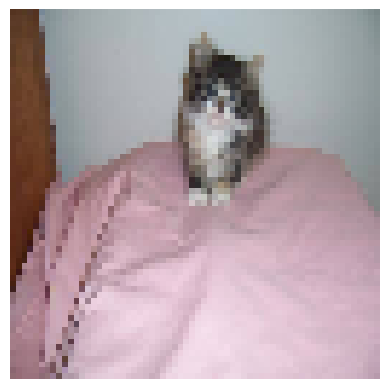

In [34]:
import matplotlib.pyplot as plt

my_image_path = r"datasets\test\cats\cats_00013.jpg"
img = cv2.imread(my_image_path)

if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_resized = cv2.resize(img, (64, 64))
    X_single = img_resized.reshape(64 * 64 * 3, 1) / 255.

    my_prediction = predict(X_single, None, parameters)

    result = int(np.squeeze(my_prediction))

    print(f"Model y = {result}")
    if result == 1:
        print("=> Dog")
    else:
        print("=> Cat")
        
    plt.imshow(img_resized)
    
    plt.axis('off')
    plt.show()
else:
    print("Cannot read")
